In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier
import pickle

Loading the CSV:

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [3]:
df.head(1)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No


In [4]:
df.drop(columns=["customerID"], inplace=True)

In [5]:
print(len(df[df["TotalCharges"]==" "]))

11


In [6]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", "0.0")

In [7]:
df["TotalCharges"] = df["TotalCharges"].astype(float)

<Axes: xlabel='Churn', ylabel='count'>

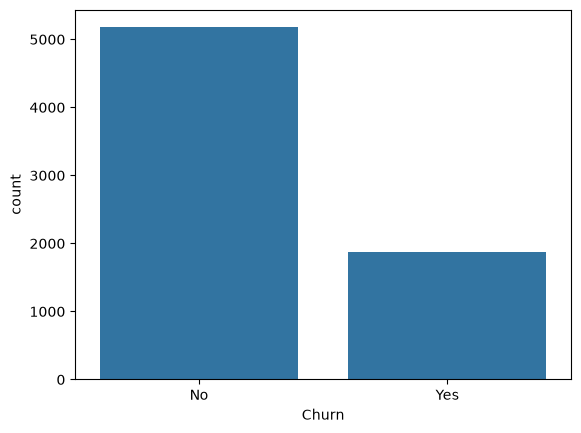

In [8]:
sns.countplot(x = df["Churn"])

In [9]:
df["Churn"] = (
    df["Churn"]
    .astype(str)
    .str.strip()
    .map({"Yes": 1, "No": 0, "1": 1, "0": 0})
)

print(df["Churn"].value_counts(dropna=False))

df["Churn"] = df["Churn"].astype("int64")

Churn
0    5174
1    1869
Name: count, dtype: int64


In [10]:
df.head(3)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


In [11]:
X = df.drop(columns=["Churn"])
Y = df["Churn"]

# First split: 80% training/validation, 20% testing
X_train_val, X_test, Y_train_val, Y_test = train_test_split(
    X,
    Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

# Second split: 80% training, 20% validation
X_train, X_val, Y_train, Y_val = train_test_split(
    X_train_val,
    Y_train_val,
    test_size=0.2,
    random_state=42,
    stratify=Y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("\nChurn distribution in training data:")
print(Y_train.value_counts(normalize=True))

Training samples: 4507
Validation samples: 1127
Testing samples: 1409

Churn distribution in training data:
Churn
0    0.734635
1    0.265365
Name: proportion, dtype: float64


training


In [12]:
numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [13]:
scale_pos_weight = (Y_train == 0).sum() / (Y_train == 1).sum()

models = {
    "Random Forest + SMOTE": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost + SMOTE": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest + SMOTE + Balanced": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost + SMOTE + Weighted": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])

    pipeline.fit(X_train, Y_train)

    y_val_prob = pipeline.predict_proba(X_val)[:, 1]
    y_val_pred = (y_val_prob >= 0.5).astype(int)

    trained_models[model_name] = pipeline

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(Y_val, y_val_pred),
        "Precision": precision_score(Y_val, y_val_pred),
        "Recall": recall_score(Y_val, y_val_pred),
        "F1 Score": f1_score(Y_val, y_val_pred),
        "ROC-AUC": roc_auc_score(Y_val, y_val_prob)
    })

results_df = pd.DataFrame(results)

display(results_df.sort_values("ROC-AUC", ascending=False))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
1,XGBoost + SMOTE,0.809228,0.668000,0.558528,0.608379,0.846841
3,XGBoost + SMOTE + Weighted,0.754215,0.525581,0.755853,0.620027,0.844465
2,Random Forest + SMOTE + Balanced,0.785271,0.619247,0.494983,0.550186,0.822248
0,Random Forest + SMOTE,0.786158,0.621849,0.494983,0.551210,0.822135


EVALUATION

Selected Model: XGBoost + SMOTE

Optimal Threshold: 0.3799999999999999
Validation F1 Score: 0.6541471048513302


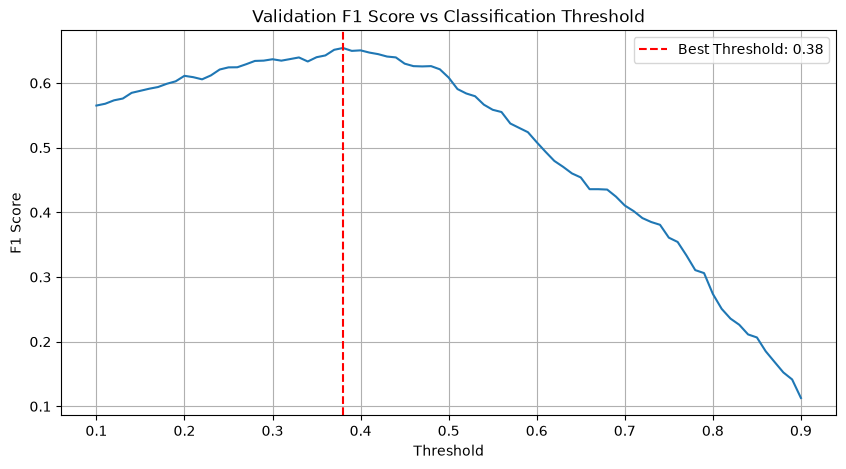


FINAL TEST RESULTS
-------------------------
Model: XGBoost + SMOTE
Threshold: 0.3799999999999999
Accuracy: 0.7771469127040455
Precision: 0.5635593220338984
Recall: 0.7112299465240641
F1 Score: 0.6288416075650118
ROC-AUC: 0.8429086259009533

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1035
           1       0.56      0.71      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409

Confusion Matrix:


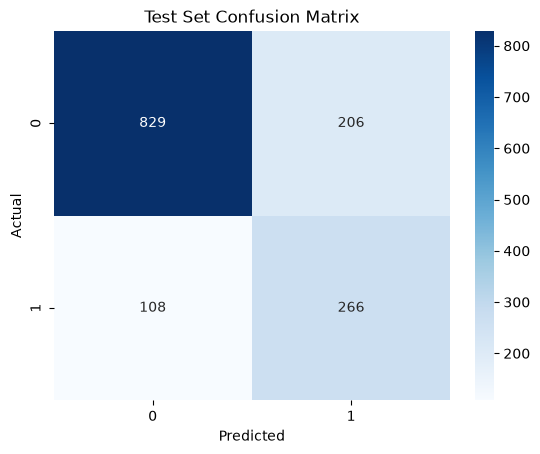

In [14]:
# Select best model using validation ROC-AUC
best_model_name = results_df.loc[
    results_df["ROC-AUC"].idxmax(), "Model"
]

best_model = trained_models[best_model_name]

print("Selected Model:", best_model_name)

# Get validation probabilities
y_val_prob = best_model.predict_proba(X_val)[:, 1]

# Find the threshold that maximizes validation F1-score
thresholds = np.arange(0.10, 0.91, 0.01)

f1_scores = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    f1_scores.append(f1_score(Y_val, y_val_pred))

best_threshold = thresholds[np.argmax(f1_scores)]

print("\nOptimal Threshold:", best_threshold)
print("Validation F1 Score:", max(f1_scores))

# Plot threshold vs F1-score
plt.figure(figsize=(10, 5))

plt.plot(thresholds, f1_scores)

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best Threshold: {best_threshold:.2f}"
)

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("Validation F1 Score vs Classification Threshold")
plt.legend()
plt.grid()
plt.show()


# FINAL TEST EVALUATION
# Test set is used only here

y_test_prob = best_model.predict_proba(X_test)[:, 1]

y_test_pred = (y_test_prob >= best_threshold).astype(int)

print("\nFINAL TEST RESULTS")
print("-------------------------")

print("Model:", best_model_name)
print("Threshold:", best_threshold)

print("Accuracy:", accuracy_score(Y_test, y_test_pred))
print("Precision:", precision_score(Y_test, y_test_pred))
print("Recall:", recall_score(Y_test, y_test_pred))
print("F1 Score:", f1_score(Y_test, y_test_pred))
print("ROC-AUC:", roc_auc_score(Y_test, y_test_prob))

print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))

print("Confusion Matrix:")
sns.heatmap(
    confusion_matrix(Y_test, y_test_pred),
    annot=True,
    fmt="d",
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Test Set Confusion Matrix")
plt.show()

Top 15 Features Influencing Customer Churn:


,Feature,Importance
36,cat__Contract_Month-to-month,0.299818
27,cat__TechSupport_No,0.076811
18,cat__OnlineSecurity_No,0.073803
16,cat__InternetService_Fiber optic,0.043666
43,cat__PaymentMethod_Electronic check,0.043174
9,cat__Dependents_Yes,0.036919
21,cat__OnlineBackup_No,0.032757
13,cat__MultipleLines_No phone service,0.025421
29,cat__TechSupport_Yes,0.023342
40,cat__PaperlessBilling_Yes,0.021062


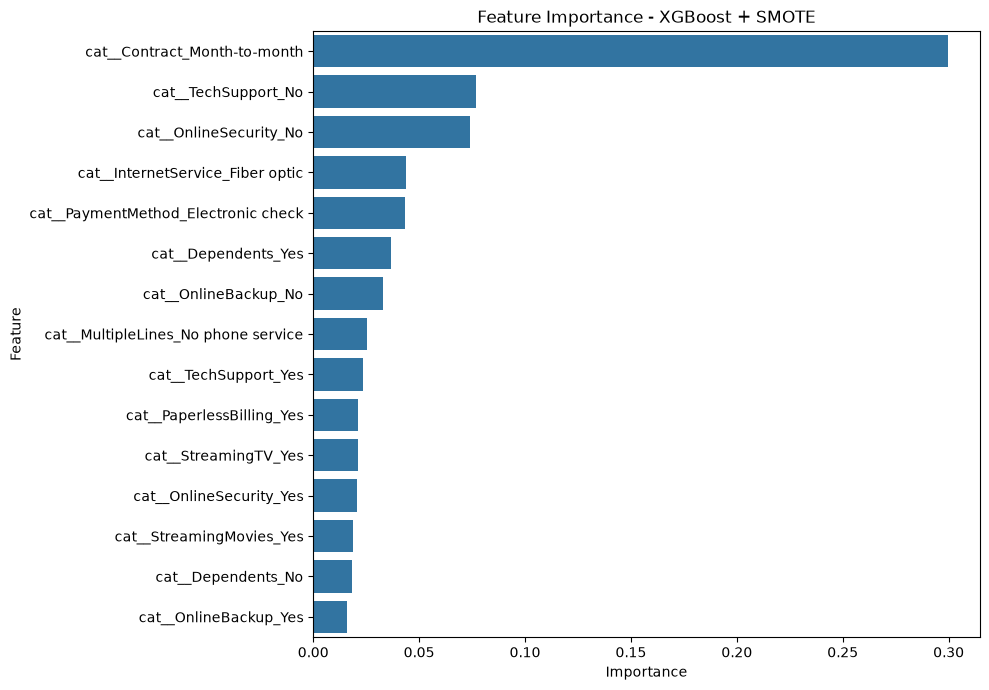

In [15]:
# Get the trained classifier
model = best_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Extract feature importance
importances = model.feature_importances_

# Create importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
top_features = feature_importance_df.head(15)

print("Top 15 Features Influencing Customer Churn:")
display(top_features)

# Plot feature importance
plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(f"Feature Importance - {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [16]:
with open("customer_churn_model.pkl", "wb") as f:
    pickle.dump(best_model, f)